# 智能体：让模型选择工具并完成多步任务


## 从回答问题，到完成任务

第 05 章已经说明：模型可以提出工具调用请求，但工具仍由程序执行。若一项任务需要“查客户 → 判断等级 → 处理业务 → 汇总结果”，应用就要反复把工具结果交回模型，继续下一步。

**Agent（智能体）把模型决策、工具执行和状态更新组织成一个循环。** 模型根据当前上下文选择下一步，程序执行相应工具，直到形成最终答案或满足结束条件。

~~~text
普通模型调用：输入 → 模型 → 回答
工具型 Agent：输入 → 模型选择工具 → 执行工具 → 模型继续判断 → 最终结果
~~~

本篇根据尚硅谷第 07 章《智能体》的 83 页课件整理，主线是 LangChain 1.x 的 `create_agent`。前面手写的工具循环，现在交给 Agent 管理；第 06 章的结构化输出，也会接入 Agent 的最终结果。

代码全部放在 Markdown 围栏中，仅作阅读示例，不执行程序或调用模型服务。课件的重复调用日志压缩为关键消息与流程。


## Agent 的几个组成部分

| 要素 | 负责什么 | 在本章中的体现 |
| --- | --- | --- |
| 模型 | 理解目标，选择工具与参数，解释结果 | 聊天模型与工具调用能力 |
| 工具 | 查询数据或执行确定的业务操作 | 天气、搜索、计算、客户查询 |
| 状态与记忆 | 保存当前任务的消息和其他数据 | `messages`，手工历史或 checkpointer |
| 规划 | 决定先做什么、结果是否足够 | 根据上下文继续调用工具或结束 |
| 执行流程 | 把上述步骤连接起来 | LangGraph 中的模型节点与工具节点 |

课件架构图展示了常见设计要素，**不表示 `create_agent` 默认就拥有长期记忆、反思或多智能体协作。** 各项能力要按任务配置。

最小 Agent 可以不提供工具；需要天气、数据库等外部能力时，才把相应工具加入。长期记忆也不等于保存全部聊天记录，更不只限于向量数据库。

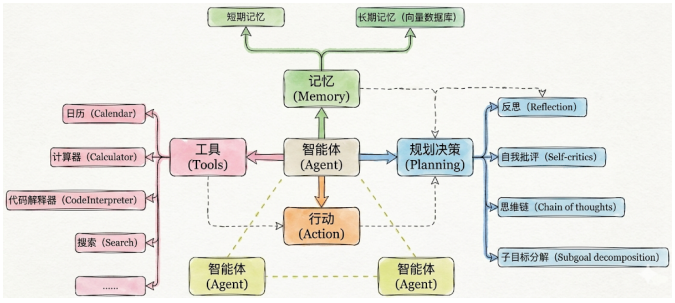

课件第 2 页：Agent 的常见设计要素。


## 从旧版 AgentExecutor 到 create_agent

课件先对比了 LangChain 0.x 的创建方式：按不同场景选择 `create_react_agent`、`create_tool_calling_agent` 等，再配合 `AgentExecutor`、提示词和执行器管理调用。

LangChain 1.x 的主入口是：

~~~python
from langchain.agents import create_agent
~~~

`create_agent` 在 LangGraph 上构建运行图，返回可调用的 `CompiledStateGraph`。因此它除了支持 `.invoke()`，还可以流式运行、保存检查点，并通过 middleware 扩展行为。

“ReAct”强调推理与行动交替：根据已有信息决定行动，获得结果后再判断。这里的模型—工具循环体现了这种思路；不需要自己把一套旧版 scratchpad 提示词搬进新接口。不同包里的同名历史 API 也不要混用。


## 本章公共配置：模型对象更方便控制服务地址

沿用前面 OpenAI 兼容服务的配置方式。工具示例要求所选模型和服务支持工具调用；结构化示例还要求对应输出策略得到支持。

~~~bash
uv add langchain langchain-openai python-dotenv pydantic typing-extensions
~~~

~~~dotenv
CLOSEAI_API_KEY=你的模型服务密钥
CLOSEAI_BASE_URL=服务商提供的OpenAI兼容API地址
CHAT_MODEL=账户可用且支持工具调用的模型名称
~~~

~~~python
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.tools import tool

load_dotenv()
model = init_chat_model(
    model=os.environ["CHAT_MODEL"],
    model_provider="openai",
    api_key=os.environ["CLOSEAI_API_KEY"],
    base_url=os.environ["CLOSEAI_BASE_URL"],
    temperature=0,
)
~~~

后面的短示例默认已定义这里的 `model`。末尾综合助手另给出可合并为独立脚本的完整配置。

`model` 也可以传带提供商前缀的字符串，例如 `"openai:账户可用的模型名"`。字符串形式适合标准配置；需要自定义 `base_url` 等参数时，先创建模型对象更直观。`temperature=0` 有助于减少随机性，不能保证每次工具轨迹完全相同。


## 最小 Agent：先不接工具

~~~python
agent = create_agent(
    model=model,
    system_prompt="你是一名中文学习助手，回答清楚、简洁。",
)

result = agent.invoke({
    "messages": [{"role": "user", "content": "用一句话解释 LangChain。"}]
})
print(result["messages"][-1].content)
~~~

创建时得到的是运行图；调用 `.invoke()` 才开始执行。**调用结果是状态字典，而不是一条 AIMessage。** 这个没有结构化输出的简单例子，正常结束时最后一条消息通常就是模型的最终回复。

提供工具并非创建 Agent 的硬性要求。没有工具时，它主要完成模型调用和消息状态管理；增加工具后，才可能进入模型—工具循环。


## create_agent 常用参数怎么分工？

| 参数 | 作用 | 使用时注意 |
| --- | --- | --- |
| `model` | 模型对象或提供商模型字符串 | 能力必须与任务匹配 |
| `tools` | 注册可使用的工具 | 可省略；描述与类型决定模型怎样理解工具 |
| `system_prompt` | 任务角色、规则、工具使用条件 | 支持字符串或 SystemMessage |
| `name` | 给 Agent 命名，便于组合与追踪 | 不等于会话 ID |
| `response_format` | 声明最终结构化输出 | 从 `structured_response` 取结果 |
| `middleware` | 在模型与工具执行环节扩展逻辑 | 动态选择、拦截、重试等属于后续扩展 |
| `checkpointer` | 保存图运行状态与检查点 | 调用时配合 `thread_id` |
| `store` | 可供图访问的存储 | 跨会话数据需要另行设计读写与隔离 |

这是一张常用参数表，不是完整签名。参数与能力随安装版本变化，查错时应同时确认 `langchain`、`langgraph` 和模型集成包的版本。

`recursion_limit` 属于运行时 `config`，不是这里的创建参数；后面会说明它怎样约束循环。


## 输入是消息，输出是状态

建议使用明确的角色与内容：

~~~python
from langchain.messages import HumanMessage

input_as_dict = {
    "messages": [{"role": "user", "content": "北京天气怎么样？"}]
}
input_as_object = {
    "messages": [HumanMessage(content="北京天气怎么样？")]
}
~~~

两种写法都可以作为输入，实际调用时选一种即可。框架也能转换某些简写形式，但显式角色更利于阅读和排查。

| 状态中的键 | 用途 |
| --- | --- |
| `messages` | 用户消息、模型消息、工具结果等消息序列 |
| `structured_response` | 配置结构化输出并成功生成后得到的结果 |
| 其他状态字段 | 由自定义状态或 middleware 引入的数据 |

普通文本回答可以读取最终 AIMessage 的 `.content`；多模态内容可能是内容块列表，应按块类型处理。不要对任何 Agent 都无条件使用 `result["messages"][-1].content`：结构化输出的末条消息可能是工具确认消息。


## 接入第一个工具：模拟天气查询

~~~python
@tool
def get_weather(city: str) -> dict:
    """查询指定城市的模拟天气；支持北京、上海、深圳，不提供实时数据。"""
    samples = {
        "北京": "多云，15～22℃",
        "上海": "晴，18～25℃",
        "深圳": "小雨，22～28℃",
    }
    city = city.strip()
    if city not in samples:
        return {"found": False, "city": city, "source": "模拟数据"}
    return {
        "found": True,
        "city": city,
        "weather": samples[city],
        "source": "模拟数据",
    }

weather_agent = create_agent(
    model=model,
    tools=[get_weather],
    system_prompt="查询天气时使用工具，明确说明是模拟数据；查不到就说明缺失。",
)
result = weather_agent.invoke({
    "messages": [{"role": "user", "content": "北京天气怎么样？"}]
})
print(result["messages"][-1].content)
~~~

与第 05 章不同，这里不需要自己 `bind_tools`、遍历 `tool_calls` 或追加 ToolMessage。`create_agent` 负责注册工具并管理这些步骤。

工具名、参数注解和 docstring 是模型选择工具的依据。这里的结果来自固定字典，回答不能把它描述成实时天气。


## Agent 内部怎样循环？

~~~text
用户消息进入 messages
    ↓
model：结合系统提示、消息历史和工具定义进行判断
    ├─ 请求业务工具 → tools 执行 → ToolMessage 回到 messages → 再调用 model
    └─ 给出最终回答 → 结束
~~~

`model` 节点提出工具调用请求；`tools` 节点负责实际运行 Python 工具。工具结果重新进入上下文，模型才知道查询到了什么。

一轮模型响应可能请求多个工具，也可能先调用一个工具，再根据结果决定下一个工具。具体执行顺序、并发行为和消息数量由任务、图与工具配置决定，不能认为每次都固定四条消息。

下图是普通工具型 Agent 的基础循环。接入结构化输出、middleware 等能力后，实际运行路径会增加相应处理。

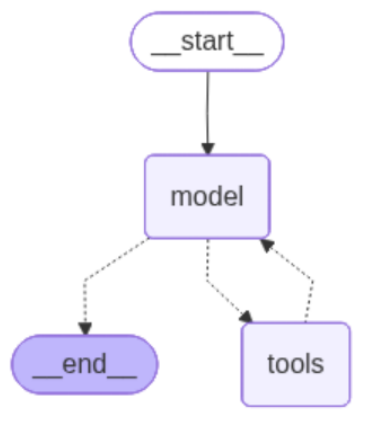

课件第 15 页：模型节点、工具节点与结束路径。


## 看消息轨迹，比只看最终答案更有用

~~~python
for message in result["messages"]:
    message.pretty_print()
~~~

一次天气查询的精简轨迹可能是：

~~~text
HumanMessage：北京天气怎么样？
AIMessage：tool_calls=[get_weather(city="北京")]
ToolMessage：{"found": true, "city": "北京", "weather": "多云，15～22℃", ...}
AIMessage：模拟天气数据显示，北京多云，气温 15～22℃。
~~~

这里省略了调用 ID、token 统计、延迟等重复元数据；这是流程示意，不是本笔记实际运行的输出。

需要重点核对三个地方：模型选的工具是否正确、参数是否正确、最终回答是否忠实于工具结果。AIMessage 的 `content` 可以为空，同时携带 `tool_calls`；空文本不等于没有有效输出。


## 多个工具：模型按问题选择需要的能力

在天气工具之外，再提供服务器时间工具：

~~~python
from datetime import datetime, timedelta, timezone

@tool
def get_current_time() -> str:
    """获取程序所在设备的当前时间，并按 UTC+8 显示。"""
    now = datetime.now(timezone(timedelta(hours=8)))
    return now.strftime("%Y-%m-%d %H:%M:%S UTC+8")

multi_agent = create_agent(
    model=model,
    tools=[get_weather, get_current_time],
    system_prompt="按需查询天气和时间；天气是模拟数据，时间来自设备时钟。",
)
result = multi_agent.invoke({
    "messages": [{"role": "user", "content": "北京天气怎样？现在几点了？"}]
})
~~~

独立的天气与时间查询可能在同一轮提出；有依赖的任务应先获得上一步结果。例如“找到客户 ID，再查询订单”，第二步的参数来自第一步，不能预先猜测。

普通业务工具可以一次调用多个；后面 `Union` 结构化输出要求最终选择一种结果类型，是另一项规则。


## 接入现成工具：Tavily 搜索

课件使用 `langchain-tavily` 集成，将网页搜索注册为 Agent 工具。需要模型服务和 Tavily 两套配置。

~~~bash
uv add langchain-tavily
~~~

~~~dotenv
TAVILY_API_KEY=你的Tavily密钥
~~~

~~~python
from langchain_tavily import TavilySearch

web_search = TavilySearch(max_results=2)
search_agent = create_agent(
    model=model,
    tools=[web_search],
    system_prompt="需要查证外部信息时使用搜索，并根据结果给出来源。",
)
result = search_agent.invoke({
    "messages": [{"role": "user", "content": "查询 2024 年诺贝尔物理学奖得主及来源。"}]
})
print(result["messages"][-1].content)
~~~

只想检查工具自身的输入输出时，可以单独调用：

~~~python
search_result = web_search.invoke({"query": "2024 Nobel Prize in Physics laureates"})
~~~

单独调用工具直接执行搜索；Agent 调用则先由模型决定搜索词，再根据结果组织答案。`max_results=2` 限制检索结果数量，不保证两条结果就足以完成所有核实。

这些是联网调用示例，本笔记没有执行搜索。可查阅 [Tavily 文档](https://docs.tavily.com/)。


## 工具越多越好吗？先看任务需要

工具生态可以覆盖搜索、网页读取、SQL、文件、日历、HTTP 接口和代码处理，但工具列表只是提供能力，不能代替清楚的任务设计。

| 工具设计问题 | 对 Agent 的影响 |
| --- | --- |
| 名称和描述过于相似 | 模型不容易判断该用哪个 |
| 参数含义模糊 | 可能猜测错误 ID、单位或日期 |
| 没有明确失败结果 | 模型可能反复调用或编造成功 |
| 一次返回过多无关数据 | 增加上下文负担，掩盖关键结果 |
| 业务工具功能太大 | 难以控制与定位失败步骤 |

课件建议先从少量工具开始，例如 2～5 个，这是便于教学和调试的经验，不是框架限制。实际应按任务提供必要工具，描述清楚适用条件、数据来源和失败状态。复杂场景可在后续通过 middleware 动态选择工具。


## 循环何时结束？怎样限制异常循环？

普通工具型 Agent 通常在模型不再提出工具调用、形成最终回答后结束。结构化输出则有相应的成功与结束路径。框架有默认执行限制，不是无限运行。

~~~python
from langgraph.errors import GraphRecursionError

try:
    result = weather_agent.invoke(
        {"messages": [{"role": "user", "content": "查询北京天气。"}]},
        config={"recursion_limit": 20},
    )
except GraphRecursionError:
    print("达到图执行步数限制，请检查工具结果和结束条件。")
~~~

`recursion_limit` 限制图执行的 supersteps，**不是工具调用次数，也不是 Python 函数递归深度。** 同一步可能运行多个工具，一次业务也可能经历多次模型调用。

遇到此异常，先检查是否一直返回模糊错误、任务是否无法完成、提示词是否要求不断搜索、结构化结果是否反复不合规。合理提高限制可以容纳长任务，但无法修复没有结束条件的循环。


## 课件的重试：模型再次调用不等于程序保证重试

课件用“前两次失败、第三次成功”的工具演示 Agent 如何根据失败反馈继续行动。下面用单次演示专用的闭包保存计数，避免所有会话共享一个全局计数器：

~~~python
def make_demo_query_tool():
    attempts = 0

    @tool
    def query_demo_status(record_id: str) -> dict:
        """查询模拟记录；TEMP_UNAVAILABLE 表示临时失败，演示中可再次尝试。"""
        nonlocal attempts
        attempts += 1
        if attempts <= 2:
            return {"ok": False, "code": "TEMP_UNAVAILABLE", "attempt": attempts}
        return {"ok": True, "record_id": record_id, "value": 42, "attempt": attempts}

    return query_demo_status

retry_agent = create_agent(
    model=model,
    tools=[make_demo_query_tool()],
    system_prompt=(
        "查询失败时读取错误码。仅 TEMP_UNAVAILABLE 可以重试，"
        "总尝试不超过 3 次；仍失败就说明原因。"
    ),
)
~~~

这里工具返回正常的错误数据，模型读到反馈后可能再次提出调用。提示词中的“3 次”是行为指令，**不能成为可靠的程序次数上限**；执行上限仍需由程序或 middleware 计数和控制。

如果工具抛出异常，是否转换成反馈、是否重试，要看工具节点和错误处理配置。网络重试应在相应调用层实现明确策略。发送邮件、扣款等有副作用的操作还需要幂等设计，不能失败后盲目重放整个 Agent。

闭包计数也仅适合这个单次演示；并发业务不能直接拿它管理多个用户的重试。


## system_prompt：把角色、工具条件和结束条件说清楚

一个有用的系统提示包含：任务范围、何时使用工具、如何处理结果，以及失败时如何结束。

~~~python
from langchain.messages import SystemMessage

system_prompt = SystemMessage(content="""
你是中文信息查询助手。
先理解用户需要查询的信息，再调用相应工具。
只依据查询结果回答，未知信息明确说明缺失。
天气工具返回未找到时，说明没有该城市的模拟数据并结束。
先完成必要查询，再形成最终回答；明确区分模拟天气和设备时间。
""")

policy_agent = create_agent(
    model=model,
    tools=[get_weather, get_current_time],
    system_prompt=system_prompt,
)
~~~

字符串与 SystemMessage 都是可用形式，不需要为同一条规则同时使用两种写法。下面的客户案例会进一步把查询、业务处理与最终报告的顺序写明。

`system_prompt` 在模型请求时提供指令，不代表一定作为普通消息长期保存在 `result["messages"]` 中。清空手工聊天历史后，创建 Agent 时设置的系统提示仍会用于后续请求。


## name：命名组件，与 thread_id 分工不同

~~~python
named_agent = create_agent(
    model=model,
    tools=[get_weather],
    name="weather_assistant",
    system_prompt="使用中文回答，并说明天气数据是模拟值。",
)
~~~

`name` 帮助在组合 Agent、消息和追踪中识别组件；具体显示位置依运行方式与版本而定。它不会自动创建聊天会话，也不是权限、唯一标识或记忆隔离机制。

需要保存某次对话的状态时，用 checkpointer，并在调用配置中传 `configurable.thread_id`。组件名可以相同，会话 ID 应按应用的对话范围独立管理。


## 模型结构化输出，与 Agent 结构化输出

第 06 章的 `.with_structured_output()` 主要解决一次模型调用的结果格式。本章通过 `response_format` 规定 Agent 完成任务后的结果格式。

| 接口 | 关注点 | 从哪里读结果 |
| --- | --- | --- |
| `model.with_structured_output(Schema)` | 一次模型调用按 Schema 生成 | 包装器 `.invoke()` 的返回值 |
| `create_agent(response_format=...)` | 工具执行与最终结构化输出共同运行 | 状态字典的 `structured_response` |

Agent 可以先调用数据库工具，再把数据整理成 Schema。**业务工具负责获得事实或执行动作，输出 Schema 负责承载最终结果。** 结构化成功只说明格式符合相应规则，不证明业务动作已真实完成。


## response_format：自动选择、原生策略与工具策略

~~~python
from pydantic import BaseModel, Field
from langchain.agents.structured_output import ProviderStrategy, ToolStrategy

class ContactInfo(BaseModel):
    """从文本中抽取的联系信息。"""
    name: str = Field(description="姓名，必须来自原文")
    email: str | None = Field(description="邮箱；原文没有则为 null")

extractor = create_agent(
    model=model,
    response_format=ToolStrategy(ContactInfo),
    system_prompt="只根据输入抽取联系信息，不补写缺失邮箱。",
)
result = extractor.invoke({
    "messages": [{"role": "user", "content": "张三的邮箱是 zhangsan@example.com。"}]
})
contact = result["structured_response"]
print(contact.name)
print(contact.model_dump())
~~~

| `response_format` 写法 | 含义 |
| --- | --- |
| `ContactInfo` | 直接传 Schema，由框架根据支持情况自动选择策略 |
| `ProviderStrategy(ContactInfo)` | 使用提供商原生结构化输出能力 |
| `ToolStrategy(ContactInfo)` | 借助工具调用协议生成结构化结果 |
| `None` 或省略 | 不要求最终结果按指定 Schema 输出 |

本章明确使用 ToolStrategy，方便衔接工具协议。ProviderStrategy 要求模型服务原生支持相应机制；指定策略不能给服务增加它没有的能力。

课件对“直接传 Schema 是否支持”的描述前后不一致。常用 LangChain 1.x API 支持直接 Schema 自动选择；自动识别依赖模型能力信息与集成，兼容网关的识别可能不准确，此时显式选策略更便于定位问题。不需要导入内部 AutoStrategy 类。


## ToolStrategy 的“输出工具”不执行真实业务

~~~text
定义 ContactInfo
    ↓ 转换为结构化输出工具的参数 Schema
模型请求 ContactInfo(name=..., email=...)
    ↓ Agent 解析与校验参数
structured_response = ContactInfo(...)
    ↓ 返回结构化输出确认消息并结束
~~~

它利用模型熟悉的工具调用协议传递数据，但 `ContactInfo` 不是发邮件或查询客户的业务工具，不需要定义一个真正执行动作的同名 Python 函数。

结构化工具和普通业务工具可以出现在同一 Agent 中，因此模型需要支持相关的工具调用与输出能力。系统提示应说明“先完成必要工具步骤，再生成最终报告”，避免尚未获得数据就提前输出。

默认的成功确认 ToolMessage 可能包含类似 `Returning structured response: ...` 的文本。应用应读取 `structured_response`，不应把这个确认文本当成最终业务对象。


## 客户分析案例：查询工具与模拟邮件工具

课件案例按“查询客户 → VIP 发送感谢邮件 → 生成分析报告”组织流程。下面保留同样业务主线，但把数据与模拟动作明确标出来。

~~~python
CUSTOMERS = {
    "张三": {"tier": "VIP", "last_purchase": "2026-01-15", "total_usd": 15000},
    "李四": {"tier": "普通", "last_purchase": "2025-12-20", "total_usd": 3200},
}

@tool
def search_customer_database(customer_name: str) -> dict:
    """按姓名精确查询模拟客户记录；未找到时返回 found=False。"""
    name = customer_name.strip()
    record = CUSTOMERS.get(name)
    if record is None:
        return {"found": False, "customer_name": name, "source": "模拟客户库"}
    return {"found": True, "customer_name": name, **record, "source": "模拟客户库"}

@tool
def send_email(customer_name: str) -> dict:
    """模拟向 VIP 客户发送感谢邮件；仅返回模拟回执，不连接任何邮件服务。"""
    name = customer_name.strip()
    if CUSTOMERS.get(name, {}).get("tier") != "VIP":
        return {"ok": False, "simulated": True, "reason": "客户不存在或不是 VIP"}
    return {"ok": True, "simulated": True, "customer_name": name}
~~~

工具输出同时表达事实和状态。`found=False` 表示记录缺失；邮件的 `ok=True` 在这个例子中只表示**模拟操作成功**。真实业务要依赖邮件服务回执，并在程序中执行权限和幂等规则。


## 客户分析案例：Schema、提示词与调用

缺失客户与正常客户应在同一套协议中表达，不能一面定义必填报告字段，一面要求“找不到就返回空对象”。

~~~python
from typing import Literal

class CustomerAnalysis(BaseModel):
    """模拟客户分析报告。"""
    found: bool = Field(description="是否查到客户")
    customer_name: str | None = Field(description="查到的客户姓名；无记录则 null")
    customer_tier: Literal["VIP", "普通"] | None = Field(description="记录中的等级；无记录则 null")
    recent_activity: str | None = Field(description="最近购买日期；无记录则 null")
    spending_level: Literal["低", "中", "高"] | None = Field(description="按规则判断；无记录则 null")
    send_email: bool = Field(description="模拟邮件工具是否返回成功回执")

analysis_agent = create_agent(
    model=model,
    tools=[search_customer_database, send_email],
    response_format=ToolStrategy(CustomerAnalysis),
    system_prompt="""
你负责模拟客户分析。先根据姓名查询客户库。
若 found=False，输出 found=False、其余客户信息为 null、send_email=False，并结束。
若找到客户，仅 VIP 客户调用 send_email；其成功回执决定 send_email 字段。
消费按美元累计金额分类：低于 5000 为低，5000 至不足 10000 为中，至少 10000 为高。
基于记录填写报告，不自行判断潜在客户或流失风险。
完成必要查询和模拟邮件步骤后，才生成最终结构化报告。
用户问题无关且没有客户姓名时，不猜姓名，按未找到的协议返回。
""",
)
result = analysis_agent.invoke({
    "messages": [{"role": "user", "content": "请分析客户张三。"}]
})
report = result["structured_response"]
print(report.model_dump())
~~~

所有可空字段仍需输出，`str | None` 的含义是“值可为 null”，不是“字段可不出现”。判断金额等级的业务规则也写明了，减少模型自行猜测分类标准。


## 客户分析结果：看状态，而不是只看一句“已发送”

对上述模拟库，按规则完成流程后，预期结果关系如下；这不是实际模型运行记录：

| 输入 | 查询状态 | 邮件步骤 | 报告重点 |
| --- | --- | --- | --- |
| 分析张三 | 找到 VIP，15000 美元 | 调用模拟邮件工具 | found=True，高，send_email=True |
| 分析李四 | 找到普通客户，3200 美元 | 不调用邮件工具 | found=True，低，send_email=False |
| 分析王五 | 未找到 | 不调用邮件工具 | found=False，客户信息为 null |
| 没有姓名的无关问题 | 不猜测客户 | 不调用邮件工具 | 按未找到协议返回 |

**最终报告是模型生成的摘要，不应成为执行副作用或判断动作成功的唯一凭据。** 真实业务还要核对查询结果、业务规则与工具回执；确定性的步骤依赖也可以在工作流中直接编码。

课件“先输出结构化结果可能导致工具未执行”提醒的是流程设计：Agent 一旦完成最终输出，就可能结束。它不是说只要把提示词的句子放到最后，就能严格保证所有业务步骤执行。


## 四种 Schema：不要照搬模型包装器的结论

Agent 的结构化策略有自己的转换与解析逻辑，和第 06 章各模型集成的 `.with_structured_output()` 不能简单等同。

| Schema | ToolStrategy 的常见结果 | 应了解的校验特点 |
| --- | --- | --- |
| Pydantic BaseModel | Pydantic 实例 | 支持字段约束与校验器 |
| TypedDict | 普通字典 | TypedDict 本身不校验；策略解析可借助 TypeAdapter 校验类型 |
| JSON Schema 字典 | 普通字典 | 没有对应 Python 类型，不应默认已完整执行客户端 Schema 校验 |
| 标准 dataclass | dataclass 实例 | 策略解析可借助 TypeAdapter；数据类自身并非自动校验器 |

具体支持范围和解析行为以安装版本为准。常用策略实现对 Python 类型通过 Pydantic TypeAdapter 解析，对原始 JSON Schema 则返回字典。因此不能笼统说“Agent 中只有 Pydantic 会校验”，也不能说“dataclass 总返回 dict”。

主线选择 Pydantic，便于表达约束并用 `.model_dump()` 转成字典；下面用同一个联系方式任务对比其他写法。


## TypedDict：用字典表示结果

~~~python
from typing import Annotated
from typing_extensions import TypedDict

class ContactDict(TypedDict):
    """联系信息字典。"""
    name: Annotated[str, ..., "姓名，来自原文"]
    email: Annotated[str | None, ..., "邮箱；原文没有则为 null"]

dict_agent = create_agent(
    model=model,
    response_format=ToolStrategy(ContactDict),
    system_prompt="只抽取原文，缺少邮箱时填 null。",
)
result = dict_agent.invoke({
    "messages": [{"role": "user", "content": "联系人是小明，没有提供邮箱。"}]
})
contact_dict = result["structured_response"]
print(contact_dict["name"])
~~~

`Annotated` 三项分别提供类型、必填标记和字段说明，这是集成转换时使用的元信息，不是给普通字典自动补默认值的 Python 语法。`email` 的值可以为 null，但仍要求出现这个键。

这里返回 dict，读取方式是下标；策略里的运行时解析与 TypedDict 自身只做类型声明，要分别理解。


## JSON Schema：显式声明数据协议

~~~python
contact_schema = {
    "title": "ContactRecord",
    "description": "从原文抽取的联系信息",
    "type": "object",
    "properties": {
        "name": {"type": "string", "description": "姓名，来自原文"},
        "email": {"type": ["string", "null"], "description": "邮箱；未知则 null"},
    },
    "required": ["name", "email"],
    "additionalProperties": False,
}

json_agent = create_agent(
    model=model,
    response_format=ToolStrategy(contact_schema),
    system_prompt="只抽取原文，不编造邮箱。",
)
~~~

这里传入的是 Python 字典，不是 `json.dumps()` 后的字符串。`title` 使用适合作为输出工具名称的英文标识，中文解释放在 `description`。

`required` 控制是否必须出现字段；`type` 包含 `null` 控制值是否可空；`additionalProperties=False` 表达不允许额外字段。服务支持的关键字可能有限，返回 dict 后若业务要求完整校验，可再用 JSON Schema 校验器明确验证。


## dataclass：数据类也能作为 Agent 的 Schema

~~~python
from dataclasses import dataclass, field, asdict

@dataclass
class ContactData:
    """联系信息数据类。"""
    name: str = field(metadata={"description": "姓名，来自原文"})
    email: str | None = field(metadata={"description": "邮箱；未知则 null"})

data_agent = create_agent(
    model=model,
    response_format=ToolStrategy(ContactData),
    system_prompt="只抽取原文，缺失邮箱填 null。",
)
result = data_agent.invoke({
    "messages": [{"role": "user", "content": "小明的邮箱是 xiaoming@example.com。"}]
})
contact_data = result["structured_response"]
print(contact_data.name)
print(asdict(contact_data))
~~~

标准 dataclass 的字段使用 `dataclasses.field`，不要把 Pydantic 的 `Field` 对象当成普通数据类默认值。此处不设默认值，字段由模型明确生成。

Agent 策略支持 dataclass，不意味着任意模型集成都能直接接收它；也不意味着手工创建 `ContactData(...)` 时，标准 dataclass 会自动按注解验证所有值。


## Union：最终选择一种结果，而不是收集全部类型

~~~python
from typing import Union

class EventDetails(BaseModel):
    """活动详情。"""
    event_name: str = Field(description="活动名称")
    date: str = Field(description="原文给出的活动日期，使用 YYYY-MM-DD")

union_agent = create_agent(
    model=model,
    response_format=ToolStrategy(Union[ContactInfo, EventDetails]),
    system_prompt="按用户指定的任务提取联系信息或活动详情，每次只返回一种结果。",
)
result = union_agent.invoke({
    "messages": [{"role": "user", "content": "请提取活动：公司年会，日期 2026-07-15。"}]
})
item = result["structured_response"]
~~~

ToolStrategy 会为候选 Schema 准备相应的输出工具，让模型选择其中一种。**成功的最终结果是一个候选类型的对象**，不是自动返回两个类型的列表。

若模型同时请求多个结构化输出工具，会触发 `MultipleStructuredOutputsError`；普通业务工具的多调用不受这个“一种最终结构化结果”的规则约束。

如果任务明确要求同时抽取联系人和活动，应定义包含 `contact`、`event` 的复合 Schema；要提取多个联系人，则定义带列表字段的 Schema。不要用 Union 表示“全部都要”。


## tool_message_content：改变成功确认文本

~~~python
brief_ack_agent = create_agent(
    model=model,
    response_format=ToolStrategy(
        ContactInfo,
        tool_message_content="联系信息提取完成。",
    ),
)
~~~

这个参数改变成功结构化输出对应的 ToolMessage 内容，避免把整个对象再次展开为确认文本。结构化结果仍保存在 `structured_response` 中。

它不会移除 AIMessage 中的工具参数，也不负责决定前端是否显示消息。不能把自定义确认文本理解为“所有敏感字段都已从历史中删除”或“整个调用一定更省 token”。显示哪些消息与保存哪些数据，仍由应用设计。


## handle_errors：结构化错误如何反馈给模型？

| 设置 | 处理方式 |
| --- | --- |
| `True`，默认 | 处理结构化输出错误，把错误反馈给模型继续修正 |
| `False` | 不做该类反馈重试，向调用方抛出错误 |
| 固定字符串 | 使用这段文字作为错误反馈 |
| 异常类型 | 仅处理匹配的错误类型 |
| 异常类型元组 | 处理元组中匹配的错误类型 |
| `Callable[[Exception], str]` | 根据异常生成反馈文字；也可以主动抛出异常 |

常见的两类错误：

- `MultipleStructuredOutputsError`：一次生成了多个最终结构化响应。
- `StructuredOutputValidationError`：结构化输出不符合对应 Schema。

~~~python
from langchain.agents.structured_output import (
    MultipleStructuredOutputsError,
    StructuredOutputValidationError,
)

strategy = ToolStrategy(
    ContactInfo,
    handle_errors=(StructuredOutputValidationError, MultipleStructuredOutputsError),
)
~~~

`handle_errors` 处理的是**结构化输出错误**，不是所有业务工具、网络和鉴权异常。反馈后模型可能修正，也可能再次失败；不能认为会无限重试直到成功，运行仍受图执行限制等条件约束。

元组只有一个类型时写 `(StructuredOutputValidationError,)`；没有逗号的括号只是普通分组。


## 自定义结构化错误反馈：明确告诉模型改哪里

~~~python
def structured_error_feedback(error: Exception) -> str:
    if isinstance(error, MultipleStructuredOutputsError):
        return "最终结果只能选择一种类型，请按用户的提取目标返回一个结构化响应。"
    if isinstance(error, StructuredOutputValidationError):
        return "字段不符合 Schema，请根据输入修正类型和必填字段；缺失信息按可空规则填写。"
    raise error

feedback_agent = create_agent(
    model=model,
    response_format=ToolStrategy(
        Union[ContactInfo, EventDetails],
        handle_errors=structured_error_feedback,
        tool_message_content="提取完成。",
    ),
)
~~~

错误处理器返回的字符串会用于反馈；主动抛出异常则让调用方处理。反馈应指出“只能返回一种类型”或“字段类型不合规”，不能仅重复“出错了”。

如果用户本来就要两种结果，应修改 Schema，而不是让模型反复被迫丢弃一半数据。对错误输入也不要要求模型编造值来通过校验。


## 流式输出：既能看回答，也能看执行进度

Agent 可能多次调用模型和工具。`.invoke()` 等待结束后一次返回；`.stream()` 可以逐步产生运行数据，减少界面一直等待的时间。

| stream_mode | 主要输出 | 适合用途 |
| --- | --- | --- |
| `values` | 当前完整状态快照 | 查看每步状态、读取阶段结果 |
| `updates` | 节点名与节点返回的增量 | 展示模型与工具的执行进度 |
| `messages` | 模型消息片段与元数据 | 逐步展示生成文本 |
| `custom` | 工具或节点主动发出的业务数据 | 报告处理进度、分批完成情况 |
| `tasks` | 图任务开始、完成、结果与错误等事件 | 诊断任务执行 |
| `checkpoints` | 检查点事件与保存的状态 | 检查状态保存过程 |
| `debug` | 任务与检查点等综合诊断事件 | 调试运行图 |

下面的 `.stream()` 示例使用课件的常规事件格式。组合模式按 `(mode, data)` 解包；若新版本显式启用另一种流协议，应按对应版本文档处理事件结构。

`create_agent` 常用默认流模式是 `updates`，笔记仍显式指定。注意：**每执行一次 `.stream()` 都是一轮新的 Agent 调用**；把不同模式的示例分别运行，并不是在观察同一个已完成的请求。


## 流式示例共用：三个模拟客户工具

课件用客户基本信息、订单和优惠三个查询来观察模型与工具步骤。下面把数据限定为一个模拟客户，并为未知 ID 给出明确失败结果。

~~~python
@tool
def query_customer_data(customer_id: str) -> dict:
    """查询模拟客户基本信息，仅支持 CUST123456。"""
    if customer_id != "CUST123456":
        return {"found": False, "customer_id": customer_id}
    return {"found": True, "name": "张三", "level": "VIP", "source": "模拟数据"}

@tool
def check_order_history(customer_id: str) -> dict:
    """查询模拟客户订单汇总，仅支持 CUST123456。"""
    if customer_id != "CUST123456":
        return {"found": False, "customer_id": customer_id}
    return {"found": True, "total_orders": 15, "total_spent_cny": 25800, "source": "模拟数据"}

@tool
def get_current_promotions() -> dict:
    """返回固定的模拟优惠列表，不代表真实有效的促销。"""
    return {"promotions": ["老用户优惠", "会员专属折扣"], "source": "模拟数据"}

customer_tools = [query_customer_data, check_order_history, get_current_promotions]
customer_service_agent = create_agent(
    model=model,
    tools=customer_tools,
    system_prompt="按问题查询所需信息，说明数据是模拟值；未找到时不要反复查询。",
)
stream_input = {
    "messages": [{"role": "user", "content": "查询 CUST123456 的基本信息、订单和优惠。"}]
}
~~~

以下各模式沿用这三个工具、这个 Agent 和输入，诊断示例会另建带 checkpointer 的 Agent。


## values：每次拿到的是状态快照

~~~python
for state in customer_service_agent.stream(stream_input, stream_mode="values"):
    messages = state.get("messages", [])
    print("当前消息数：", len(messages))
    if messages:
        print("最近消息类型：", messages[-1].type)
        print("最近消息内容：", messages[-1].content)
~~~

`state` 包含当前状态值；同一批旧消息可能出现在后面的多个快照中。如果每次都把全部 `messages` 追加到界面，会重复显示历史。

可以根据消息 ID 或当前长度更新展示；这里仅打印最近消息帮助观察。状态快照能用于读取阶段数据，但 **选择 values 模式本身不会启用持久化**，保存与恢复仍由 checkpointer 或应用存储负责。


## updates：看哪个节点刚刚产生了更新

~~~python
for update in customer_service_agent.stream(stream_input, stream_mode="updates"):
    for node_name, delta in update.items():
        print("节点：", node_name)
        if not isinstance(delta, dict):
            continue
        for message in delta.get("messages", []):
            print(message.type, message.content)
            if getattr(message, "tool_calls", None):
                print("工具请求：", message.tool_calls)
        if "structured_response" in delta:
            print("结构化结果：", delta["structured_response"])
~~~

常见节点名是 `model` 与 `tools`，实际名称与事件内容可能随图配置改变。这里输出的是**这个节点本次返回的增量**，不是每一步的全部历史。

它适合在页面上显示“模型选择工具”“工具返回结果”“形成答案”等可观察进度。工具请求与结果可以用来解释动作过程，不能把这些事件当成模型内部全部推理的记录。


## messages：接收文本片段和来源元数据

~~~python
for chunk, metadata in customer_service_agent.stream(
    stream_input,
    stream_mode="messages",
):
    for block in chunk.content_blocks:
        if block.get("type") == "text":
            print(block["text"], end="", flush=True)
print()
~~~

`messages` 模式的每项通常是 `(message_chunk, metadata)`，其中元数据可包含 `langgraph_node`，帮助判断片段来自哪个节点。

生成片段并不保证“一次一个字”或“一次恰好一个 token”。模型可能同时产生文本片段、工具调用片段和其他内容块；上面只展示文本，不把工具参数当成对用户的回答。

业务工具执行仍由 Agent 管理。不要看到尚未拼完整的工具调用参数片段，就自行执行工具；这会与 Agent 的工具执行重复。


## checkpoints、tasks 与 debug：诊断图的执行

检查点流需要启用 checkpointer。为便于同时观察任务和保存状态，下面的诊断 Agent 统一使用内存检查点存储。

~~~python
from langgraph.checkpoint.memory import InMemorySaver

diagnostic_agent = create_agent(
    model=model,
    tools=customer_tools,
    checkpointer=InMemorySaver(),
)
config = {"configurable": {"thread_id": "customer-stream-demo-01"}}

for mode, data in diagnostic_agent.stream(
    stream_input,
    config=config,
    stream_mode=["checkpoints", "tasks", "debug"],
):
    print(mode, data)
~~~

- `checkpoints` 观察保存的状态及相关元信息。
- `tasks` 观察图任务开始与完成，不等于用户的一整个业务任务。
- `debug` 包含更综合的诊断事件；上面同时订阅它与 tasks/checkpoints，会看到内容重叠，实际可按需要选择。

`InMemorySaver` 只在当前进程内保存，不提供进程重启后的磁盘持久化。`thread_id` 标识被保存的对话状态；同一线程后续通常只传新增用户消息，由图加载历史。不要又传整份历史，把同一轮内容重复写入。

这些诊断模式的可用范围和事件字段以安装的 LangGraph 版本为准；需要任务或检查点数据时，应检查实际配置与输出，不能靠打印模式名就判断状态已保存。


## custom：工具内部主动发送业务进度

当工具要处理一批记录时，模型文本流无法告诉用户业务处理到了哪一步。可以在工具内部使用 `get_stream_writer()` 发送自定义事件。

~~~python
from langgraph.config import get_stream_writer

@tool
def generate_sales_report() -> dict:
    """生成模拟销售报告，并发送分阶段进度。"""
    writer = get_stream_writer()
    stages = ["读取模拟数据", "汇总销售额", "整理报告"]
    for index, stage in enumerate(stages, 1):
        writer({
            "task": "sales_report",
            "stage": stage,
            "completed": index,
            "total": len(stages),
        })
    return {"revenue_cny": 1500000, "growth_percent": 12, "source": "模拟数据"}

reporting_agent = create_agent(model=model, tools=[generate_sales_report])
for progress in reporting_agent.stream(
    {"messages": [{"role": "user", "content": "请生成模拟销售报告。"}]},
    stream_mode="custom",
):
    print(progress)
~~~

writer 发送的是业务进度，工具的 `return` 则是给 Agent 的执行结果，二者用途不同。这里用计数表达完成了 1/3、2/3、3/3，不把 75% 写成最终完成。

`get_stream_writer()` 需要图执行上下文；这个工具是供 Agent 在图内调用的，不要在图外直接 `.invoke()` 来试它。示例省略了人为 sleep，实际耗时由业务处理决定。


## 组合模式：同一次调用观察两种数据

~~~python
for mode, data in customer_service_agent.stream(
    stream_input,
    stream_mode=["updates", "messages"],
):
    if mode == "updates":
        print("\n步骤更新：", data)
    elif mode == "messages":
        chunk, metadata = data
        for block in chunk.content_blocks:
            if block.get("type") == "text":
                print(block["text"], end="", flush=True)
~~~

常规组合模式逐项产生 **`(mode, data)` 元组**，不是“以模式为 key 的字典”。而 `messages` 自身的数据又是 `(chunk, metadata)`，需要再解包一层。

这样可以在一次运行中同时展示步骤和文本。需要“工具进度 + 模型回答”时，可组合 `custom` 与 `messages`；要读最终结构化结果，可订阅 updates/values 并检查相应字段。


## 实战：多功能助手的脚本组织

课件最后把天气、计算、时间、汇率与搜索整合成一个可持续对话的助手。下面保留这五种功能，按职责拆成六段 Markdown 代码块：**配置 → 天气与搜索 → 计算 → 时间与汇率 → 助手类 → 主程序**。

如果以后需要自行运行，只合并这六段到同一个 Python 文件，按顺序复制；不需要把前面的同名演示工具再复制进去。本笔记不执行这些代码。

| 功能 | 数据来源或规则 |
| --- | --- |
| 天气 | 固定模拟字典 |
| 信息搜索 | 本地模拟条目，不联网 |
| 计算 | 限定的算术表达式解析 |
| 时间 | 设备时钟，固定按 UTC+8 显示 |
| 汇率转换 | 固定模拟汇率表 |
| 对话历史 | 手工保存 Agent 返回的完整消息列表 |

这一版只使用手工消息历史，没有同时开启 checkpointer；`reset` 清空历史，Agent 的系统提示仍保留。


### 第一段：导入与模型配置

依赖和 `.env` 与本章公共配置一致；本实战的搜索不使用 Tavily，因此不需要 Tavily 密钥。

~~~python
import ast
import math
import operator
import os
from datetime import datetime, timedelta, timezone
from typing import Literal

from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage
from langchain.tools import tool


def build_model():
    load_dotenv()
    return init_chat_model(
        model=os.environ["CHAT_MODEL"],
        model_provider="openai",
        api_key=os.environ["CLOSEAI_API_KEY"],
        base_url=os.environ["CLOSEAI_BASE_URL"],
        temperature=0,
    )
~~~

把模型创建放进函数，便于由助手类统一初始化。模型名从配置读取，不把课件示例名当成所有账户都能使用的默认模型。


### 第二段：天气与本地搜索工具

~~~python
@tool
def get_weather(city: str) -> dict:
    """查询固定模拟天气，支持北京、上海、深圳；不是实时天气。"""
    data = {"北京": "多云，15～22℃", "上海": "晴，18～25℃", "深圳": "小雨，22～28℃"}
    city = city.strip()
    return {
        "found": city in data,
        "city": city,
        "weather": data.get(city),
        "source": "模拟天气",
    }


@tool
def search_info(keyword: str, category: Literal["product", "news", "all"] = "all") -> dict:
    """在本地模拟条目中搜索产品或新闻，不联网、不提供最新信息。"""
    records = [
        {"category": "product", "text": "模拟产品：手机 A，示例价格 3999 元"},
        {"category": "product", "text": "模拟产品：笔记本 B，示例价格 5999 元"},
        {"category": "news", "text": "模拟新闻：AI 应用课程开始报名"},
    ]
    keyword = keyword.strip()
    if not keyword:
        return {"found": False, "items": [], "source": "本地模拟条目"}
    items = [
        row for row in records
        if (category == "all" or row["category"] == category)
        and keyword.casefold() in row["text"].casefold()
    ]
    return {"found": bool(items), "items": items, "source": "本地模拟条目"}
~~~

`Literal` 给搜索分类提供可选值，结果显式带 `source`。课件把固定产品和新闻写在 Python 字典里，它们同样是模拟数据，不应在最终回答中称为当前行情或最新新闻。


### 第三段：用有限语法解析算术表达式

课件通过 `eval` 计算表达式。这里改为检查 AST，只允许数字、括号、`+ - * / **`、正负号，以及单参数的 `sqrt`、`abs`；其他语法直接拒绝。

~~~python
_BINARY_OPS = {
    ast.Add: operator.add,
    ast.Sub: operator.sub,
    ast.Mult: operator.mul,
    ast.Div: operator.truediv,
}
_UNARY_OPS = {ast.UAdd: operator.pos, ast.USub: operator.neg}
_MATH_FUNCTIONS = {"sqrt": math.sqrt, "abs": abs}


def _checked_number(value):
    if type(value) not in (int, float):
        raise ValueError("只接受实数")
    value = float(value)
    if not math.isfinite(value) or abs(value) > 1e12:
        raise ValueError("数值必须有限，绝对值不超过 1e12")
    return value


def _calculate_node(node):
    if isinstance(node, ast.Constant):
        return _checked_number(node.value)
    if isinstance(node, ast.UnaryOp) and type(node.op) in _UNARY_OPS:
        return _checked_number(_UNARY_OPS[type(node.op)](_calculate_node(node.operand)))
    if isinstance(node, ast.BinOp):
        left = _calculate_node(node.left)
        right = _calculate_node(node.right)
        if isinstance(node.op, ast.Pow):
            if abs(right) > 12:
                raise ValueError("指数的绝对值不超过 12")
            return _checked_number(operator.pow(left, right))
        if type(node.op) in _BINARY_OPS:
            return _checked_number(_BINARY_OPS[type(node.op)](left, right))
    if (
        isinstance(node, ast.Call)
        and isinstance(node.func, ast.Name)
        and node.func.id in _MATH_FUNCTIONS
        and len(node.args) == 1
        and not node.keywords
    ):
        value = _calculate_node(node.args[0])
        return _checked_number(_MATH_FUNCTIONS[node.func.id](value))
    raise ValueError("表达式包含不支持的语法")


@tool
def calculator(expression: str) -> dict:
    """计算有限算术表达式，支持 + - * / **、括号、sqrt(x)、abs(x)。"""
    try:
        expression = expression.strip()
        if not expression or len(expression) > 160:
            raise ValueError("表达式长度必须为 1～160 个字符")
        tree = ast.parse(expression, mode="eval")
        if sum(1 for _ in ast.walk(tree)) > 80:
            raise ValueError("表达式过于复杂")
        value = _calculate_node(tree.body)
        return {"ok": True, "expression": expression, "result": value}
    except (SyntaxError, ValueError, TypeError, ArithmeticError) as error:
        return {"ok": False, "error": str(error)}
~~~

代码没有执行表达式字符串，而是递归计算被允许的节点。长度、节点数、指数与中间结果也有上限。它是受限的教学计算器，使用浮点数，不是任意 Python 解释器或精确财务计算工具。

例如 `(25 + 17) * 3` 应得到 126，`sqrt(16)` 应得到 4；除零、负数开平方或未注册的函数应返回错误。增加函数时，需要显式注册并约束参数，不能重新放开任意执行。


### 第四段：时间与模拟汇率

~~~python
@tool
def get_time_info(
    query_type: Literal["current", "date", "tomorrow", "yesterday", "weekday"] = "current",
) -> str:
    """读取设备时钟，按 UTC+8 返回当前时间、日期、相邻日期或星期。"""
    now = datetime.now(timezone(timedelta(hours=8)))
    if query_type == "current":
        return now.strftime("%Y-%m-%d %H:%M:%S UTC+8")
    if query_type == "weekday":
        return ["星期一", "星期二", "星期三", "星期四", "星期五", "星期六", "星期日"][now.weekday()]
    offsets = {"date": 0, "tomorrow": 1, "yesterday": -1}
    if query_type not in offsets:
        return "不支持该时间查询类型"
    return (now + timedelta(days=offsets[query_type])).strftime("%Y-%m-%d UTC+8")


@tool
def convert_currency(amount: float, from_curr: str, to_curr: str) -> dict:
    """按固定模拟汇率转换金额，支持 CNY/USD/EUR/GBP/JPY/HKD，不提供实时汇率。"""
    rates = {"CNY": 1.0, "USD": 0.14, "EUR": 0.13, "GBP": 0.11, "JPY": 20.8, "HKD": 1.09}
    source = from_curr.strip().upper()
    target = to_curr.strip().upper()
    if not math.isfinite(amount) or amount < 0:
        return {"ok": False, "error": "金额必须是非负有限数"}
    if source not in rates or target not in rates:
        return {"ok": False, "error": "不支持该货币代码"}
    converted = amount / rates[source] * rates[target]
    if not math.isfinite(converted):
        return {"ok": False, "error": "转换结果超出范围"}
    return {
        "ok": True,
        "amount": amount,
        "from": source,
        "to": target,
        "converted": round(converted, 2),
        "source": "固定模拟汇率，不含手续费",
    }
~~~

汇率表的含义是“1 CNY 等于多少目标货币单位”。因此转换分两步：先用 `amount / rates[source]` 得到 CNY，再乘目标汇率。

例如模拟汇率下，100 USD → CNY 为 `100 / 0.14 × 1 ≈ 714.29`。这只解释计算方向；真实金融业务要使用明确时点的汇率、手续费和金额精度规则。


### 第五段：封装 Agent 与对话历史

~~~python
class SmartAssistant:
    """使用手工消息历史的多功能教学助手。"""

    def __init__(self):
        self.model = build_model()
        self.agent = create_agent(
            model=self.model,
            tools=[get_weather, calculator, get_time_info, convert_currency, search_info],
            system_prompt="""
你是中文多功能助手。天气查询、计算、时间查询、换汇和信息搜索使用对应工具。
独立查询可以分别完成；有参数依赖时先获得上一步结果。
天气、汇率和搜索都是模拟数据，回答时必须说明来源，不称为实时结果。
时间来自设备时钟；计算失败、记录缺失时如实说明，不编造成功。
用户信息不足时先询问必要参数。工具得到结果后，再用清楚的中文回答。
""",
            name="smart_assistant",
        )
        self.messages = []

    def chat(self, user_input: str) -> str:
        text = user_input.strip()
        if not text:
            return "请输入问题。"
        pending_messages = [*self.messages, {"role": "user", "content": text}]
        result = self.agent.invoke(
            {"messages": pending_messages},
            config={"recursion_limit": 30},
        )
        self.messages = list(result["messages"])
        for message in reversed(self.messages):
            if isinstance(message, AIMessage) and not message.tool_calls:
                answer = "".join(
                    block["text"] for block in message.content_blocks
                    if block.get("type") == "text"
                )
                return answer or "本轮完成，但没有可显示的文本回答。"
        return "本轮没有形成最终文本回答。"

    def reset(self):
        self.messages = []
~~~

先构造 `pending_messages`，调用成功后才更新历史。这样异常时不会把同一条用户输入提前写进历史，再在下一次重试中重复添加。

`result["messages"]` 已包含本轮完整消息，应该替换保存的历史，不能 `extend` 到旧历史后面。工具结果也属于上下文，不能只保留用户问题和最终回答。

这个助手没有配置结构化输出，正常完成后寻找无工具请求的最终 AIMessage 并提取文本。以后若加 `response_format`，应改从 `structured_response` 读取业务结果。


### 第六段：交互主程序与 reset / quit

~~~python
def main():
    assistant = SmartAssistant()
    print("多功能教学助手：天气、计算、时间、模拟换汇和本地模拟搜索。")
    print("输入 reset 清空对话，quit 退出。")
    while True:
        try:
            user_input = input("你：").strip()
        except (EOFError, KeyboardInterrupt):
            print("\n再见。")
            break
        if not user_input:
            continue
        command = user_input.casefold()
        if command == "quit":
            print("再见。")
            break
        if command == "reset":
            assistant.reset()
            print("对话历史已清空。")
            continue
        try:
            print("助手：", assistant.chat(user_input))
        except Exception as error:
            print(f"本轮调用失败：{type(error).__name__}: {error}")


if __name__ == "__main__":
    main()
~~~

课件主程序先自动发送一组演示问题，再进入交互。这里直接进入交互，便于自己逐条观察，不在启动时自动触发多次模型调用。

外围异常捕获用于交互示例提示本轮失败，不代表已经修复错误或适合重试所有操作。当前五个工具以查询与计算为主；以后增加有副作用的工具，要另行处理调用失败后的业务状态。


## 怎样观察综合助手是否按预期工作？

这组输入可以用于日后自行验证；本笔记只核对代码结构，没有运行模型或工具。

| 输入示例 | 应观察的行为 |
| --- | --- |
| 北京天气怎么样？ | 调天气工具，回答注明模拟 |
| 帮我算 `(25 + 17) * 3` | 调计算工具，结果为 126 |
| `sqrt(16)` | 得到 4，不让模型心算代替工具 |
| 算 `1 / 0` | 工具返回错误，回答说明失败 |
| 现在几点？明天日期呢？ | 按 UTC+8 读取时间或相邻日期 |
| 100 美元换人民币 | 按模拟汇率计算约 714.29 CNY，并说明来源 |
| 搜索手机产品 | 查本地模拟条目，不称为联网检索 |
| 那上海呢？ | 借已有消息理解前一轮天气语境 |
| reset 后再说“那上海呢？” | 不应声称仍记得已清空的具体上一轮 |

需要检查工具选择时，可以临时查看 `assistant.messages` 中的工具请求与结果，或使用第 03 章的 LangSmith 追踪。最终回答看起来合理，不足以说明工具实际执行正确。

手工历史会随对话增长，单个助手实例也不应混用多个用户。后续要增加会话隔离、历史裁剪或摘要；如果改用 checkpointer，就按线程加载历史并只发送新增消息，避免与手工历史双重累计。


## 常见问题：先定位失败发生在哪一层

| 现象 | 优先检查 |
| --- | --- |
| 工具始终不被调用 | 模型与网关能力、工具描述、问题是否需要工具 |
| AIMessage 文本为空 | 是否携带工具调用，是否尚未形成最终回答 |
| 工具参数错误 | 注解、字段说明、缺失参数处理、模型的实际请求 |
| 查询失败后一直循环 | 工具失败状态、系统提示、结构化错误反馈、步数限制 |
| 达到 GraphRecursionError | 当前循环路径与停止条件，不能只提高限制 |
| 找不到 structured_response | 是否配置输出策略、是否成功完成、模型与服务能力 |
| Union 输出两种结果后报错 | 最终结果只允许一种；需要两种时改复合 Schema |
| handle_errors 没处理网络错误 | 它负责结构化输出错误，网络错误在对应层处理 |
| messages 流看不到文字 | 是否正在生成工具参数，集成是否支持流式响应 |
| custom 工具单独调用报错 | get_stream_writer 是否处于图运行上下文 |
| 检查点没有按会话保存 | checkpointer 配置与 configurable.thread_id |
| 多轮消息越来越重复 | 是否重复 extend 完整返回历史，或混用两种历史管理 |

沿着“模型请求 → 工具参数 → 工具结果 → 后续模型响应 → 最终状态”定位，比只调整提示词更容易找到原因。界面上的进度展示、业务成功判断和运行日志，也应分别读取适合的数据。


## 本章回顾与面试提示

~~~text
模型：选择下一步
工具：执行确定操作
消息状态：承接输入、请求与结果
create_agent：连接模型—工具循环
response_format：规范最终结果
stream_mode：选择观察哪一种运行数据
历史或 checkpointer：承接后续对话
~~~

复习时抓住六点：

1. create_agent 是 LangChain 1.x 的常用入口，返回基于 LangGraph 的运行图。
2. 模型提出工具调用，框架执行工具并追加结果，再让模型继续判断。
3. invoke 返回状态字典；普通回答看消息，结构化结果看 structured_response。
4. ToolStrategy 借工具协议传数据，输出工具不等于真实业务工具；Union 最终选择一种类型。
5. updates 看步骤，messages 看生成片段，custom 看业务进度，checkpoints 看保存状态。
6. 反馈模型再次调用、程序异常重试与图步数限制是不同机制；历史管理也要选择一致的方式。

**面试回答“Agent 和普通工具调用有什么区别”：** 普通工具调用让模型生成工具名和参数，应用还要管理执行及后续调用。Agent 把模型决策、工具执行和状态更新组织成持续循环，可以根据结果决定下一步，并支持最终结构化输出、流式事件和状态保存。具体业务规则与动作成功仍需程序和真实工具结果保证。

整理来源：尚硅谷《第 07 章：智能体》，讲师宋红康，共 83 页。阅读定位：第 1～9 页是概念与创建，第 10～28 页是工具与执行，第 29～34 页是系统提示和命名，第 35～67 页是结构化输出，第 68～76 页是流式模式，第 76～83 页是多功能助手。

整理时修正了 Schema 直接传入、Agent 与模型包装器的校验差异、未知客户返回协议、组合流的解包方式和模拟数据来源，并替换了综合案例的 eval 计算方式。所有单元格均为 Markdown；示例未执行，没有调用模型、联网搜索或发送邮件。

可查阅：[Agent 文档](https://docs.langchain.com/oss/python/langchain/agents)、[结构化输出文档](https://docs.langchain.com/oss/python/langchain/structured-output)、[流式输出文档](https://docs.langchain.com/oss/python/langchain/streaming)、[LangGraph 持久化文档](https://docs.langchain.com/oss/python/langgraph/persistence)。
